## Cell 1 — Imports and paths

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project paths
PROJECT_ROOT = Path.cwd().parent
RAW_DATA = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA = PROJECT_ROOT / "data" / "processed"

PROCESSED_DATA.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data:", RAW_DATA)
print("Processed data:", PROCESSED_DATA)

Project root: e:\EV_Charging_Demand_Prediction
Raw data: e:\EV_Charging_Demand_Prediction\data\raw
Processed data: e:\EV_Charging_Demand_Prediction\data\processed


## Cell 2 — Check dataset files

In [4]:
print("Files in data/raw:")
for file in RAW_DATA.iterdir():
    print(file.name)

print("\nFiles in charge_1hour:")
CHARGE_1HOUR = RAW_DATA / "charge_1hour"

for file in CHARGE_1HOUR.iterdir():
    print(file.name)

Files in data/raw:
adj.csv
charge_1hour
distance.csv
zone-information.csv

Files in charge_1hour:
duration.csv
e_price.csv
occupancy.csv
s_price.csv
volume-11kw.csv
volume.csv


## Cell 3 — Load volume data

In [5]:
volume_path = CHARGE_1HOUR / "volume.csv"

volume = pd.read_csv(volume_path)

print("Volume shape:", volume.shape)

display(volume.head())

Volume shape: (4344, 276)


,time,102,104,105,106,107,108,109,110,111,...,1156,1159,1162,1163,1164,1166,1167,1168,1172,1173
0,2022-09-01 00:00:00,56.291667,11.083333,60.375000,78.750000,90.125000,71.458333,58.916667,40.250000,65.625000,...,46.666667,134.458333,43.458333,11.083333,224.875000,168.583333,9126.750000,123.666667,6.125000,71.750000
1,2022-09-01 01:00:00,50.458333,9.333333,72.625000,81.666667,100.333333,76.708333,51.916667,43.166667,67.666667,...,39.666667,151.958333,50.458333,9.916667,224.583333,168.875000,9111.000000,111.416667,5.250000,65.333333
2,2022-09-01 02:00:00,55.708333,12.833333,73.208333,89.250000,94.500000,75.833333,58.333333,43.166667,70.000000,...,46.666667,148.166667,44.333333,11.666667,223.125000,165.083333,6961.500000,113.750000,5.250000,67.083333
3,2022-09-01 03:00:00,57.750000,12.541667,67.666667,74.083333,89.541667,80.208333,62.416667,28.000000,72.333333,...,47.250000,146.708333,46.666667,12.833333,234.791667,157.791667,6510.916667,127.166667,6.125000,65.916667
4,2022-09-01 04:00:00,58.333333,11.958333,69.708333,78.166667,88.666667,75.541667,56.583333,42.000000,71.166667,...,44.916667,142.333333,45.791667,11.083333,222.250000,156.625000,6722.166667,114.333333,5.833333,64.750000


## Cell 4 — Check columns

In [6]:
print("First 10 columns:")
print(volume.columns[:10].tolist())

print("\nLast 10 columns:")
print(volume.columns[-10:].tolist())

print("\nNumber of columns:", volume.shape[1])
print("Number of zones:", volume.shape[1] - 1)

First 10 columns:
['time', '102', '104', '105', '106', '107', '108', '109', '110', '111']

Last 10 columns:
['1156', '1159', '1162', '1163', '1164', '1166', '1167', '1168', '1172', '1173']

Number of columns: 276
Number of zones: 275


## Cell 5 — Convert time

In [7]:
volume["time"] = pd.to_datetime(volume["time"])

print("Start time:", volume["time"].min())
print("End time:", volume["time"].max())

print("Number of timestamps:", volume["time"].nunique())

Start time: 2022-09-01 00:00:00
End time: 2023-02-28 23:00:00
Number of timestamps: 4344


## Cell 6 — Check time interval

In [8]:
time_diff = volume["time"].diff().dropna()

print("Time intervals:")
print(time_diff.value_counts().head())

print("\nExpected interval:", pd.Timedelta(hours=1))

Time intervals:
time
0 days 01:00:00    4343
Name: count, dtype: int64

Expected interval: 0 days 01:00:00


## Cell 7 — Missing values

In [9]:
missing_values = volume.isnull().sum()

print("Total missing values:", missing_values.sum())

print("\nColumns with missing values:")
display(missing_values[missing_values > 0])

Total missing values: 0

Columns with missing values:


Series([], dtype: int64)

## Cell 8 — Duplicate timestamps

In [10]:
duplicate_timestamps = volume["time"].duplicated().sum()

print("Duplicate timestamps:", duplicate_timestamps)

Duplicate timestamps: 0


## Cell 9 — Extract zone data

In [11]:
zone_columns = volume.columns[1:]

data = volume[zone_columns].values.astype(np.float32)

print("Data shape:", data.shape)
print("Number of zones:", len(zone_columns))

print("\nFirst 10 zone IDs:")
print(zone_columns[:10].tolist())

Data shape: (4344, 275)
Number of zones: 275

First 10 zone IDs:
['102', '104', '105', '106', '107', '108', '109', '110', '111', '115']


## Cell 10 — Basic statistics

In [12]:
volume_values = volume[zone_columns]

display(volume_values.describe())

,102,104,105,106,107,108,109,110,111,115,...,1156,1159,1162,1163,1164,1166,1167,1168,1172,1173
count,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,...,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000
mean,53.523301,7.489166,62.671181,83.553783,72.261501,58.017213,37.348659,33.436902,55.451877,6.524033,...,27.144404,116.395260,32.631579,12.944185,159.472963,117.256804,5021.093007,68.494147,8.779664,47.801748
std,17.286626,5.770512,22.429274,24.489619,27.468114,24.852961,16.244680,15.592272,18.623467,6.176009,...,12.358955,37.046108,16.548099,9.668601,52.447355,37.883801,2355.233126,35.859206,9.735380,20.119935
min,0.000000,0.000000,0.000000,5.833333,0.583333,0.000000,0.000000,0.000000,4.083333,0.000000,...,0.000000,4.666667,0.000000,0.000000,10.500000,0.000000,165.416667,0.000000,0.000000,2.916667
25%,42.000000,3.500000,49.000000,67.666667,53.083333,38.500000,25.666667,21.583333,42.000000,0.000000,...,17.500000,91.000000,19.250000,7.000000,122.500000,91.510417,3021.395833,41.416667,0.000000,32.666667
50%,55.416667,7.000000,63.000000,83.708333,70.000000,58.041667,35.000000,32.666667,56.000000,7.000000,...,25.666667,115.500000,31.500000,13.416667,160.416667,116.083333,5025.416667,63.000000,7.000000,47.250000
75%,66.500000,10.500000,77.000000,99.750000,89.250000,77.000000,49.000000,42.000000,68.541667,10.500000,...,35.000000,140.583333,45.500000,19.833333,202.416667,144.083333,6710.104167,91.000000,14.000000,63.000000
max,108.500000,28.583333,143.500000,180.250000,193.000000,115.500000,91.000000,96.833333,122.208333,35.000000,...,70.000000,222.250000,70.000000,49.000000,273.000000,238.000000,10545.750000,187.250000,41.125000,116.083333


## Cell 11 — Global statistics

In [13]:
print("Minimum charging volume:", volume_values.min().min())
print("Maximum charging volume:", volume_values.max().max())
print("Mean charging volume:", volume_values.mean().mean())
print("Standard deviation:", volume_values.stack().std())

Minimum charging volume: 0.0
Maximum charging volume: 16732.5
Mean charging volume: 261.46475161450957
Standard deviation: 859.7679125226246


## Cell 12 — Active zones

In [14]:
active_zones = (volume_values > 0).sum(axis=1)

print("Minimum active zones:", active_zones.min())
print("Maximum active zones:", active_zones.max())
print("Average active zones:", active_zones.mean())

Minimum active zones: 197
Maximum active zones: 275
Average active zones: 259.9976979742173


## Cell 13 — Total demand over time

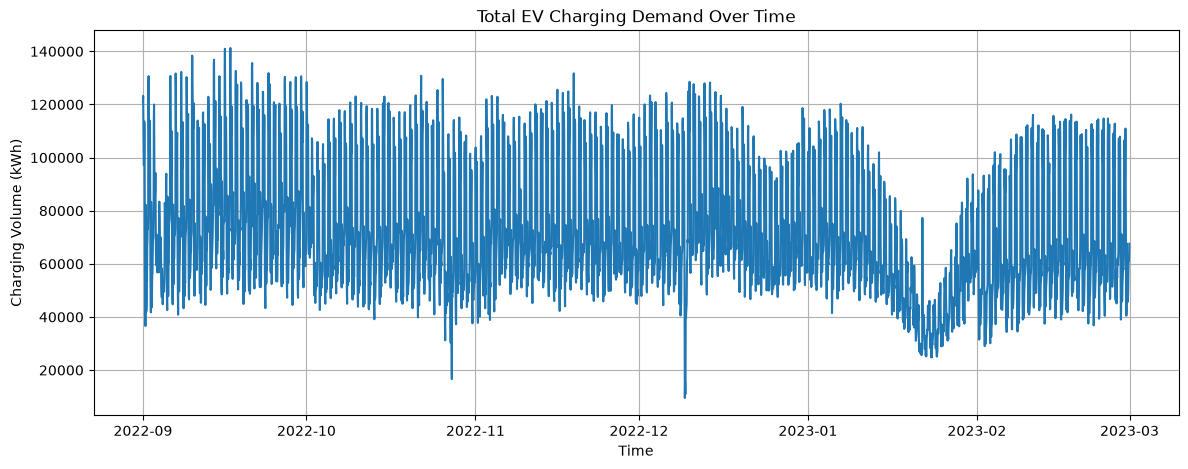

In [15]:
total_demand = volume_values.sum(axis=1)

plt.figure(figsize=(14, 5))

plt.plot(volume["time"], total_demand)

plt.title("Total EV Charging Demand Over Time")
plt.xlabel("Time")
plt.ylabel("Charging Volume (kWh)")
plt.grid(True)

plt.show()

## Cell 14 — Average demand by hour

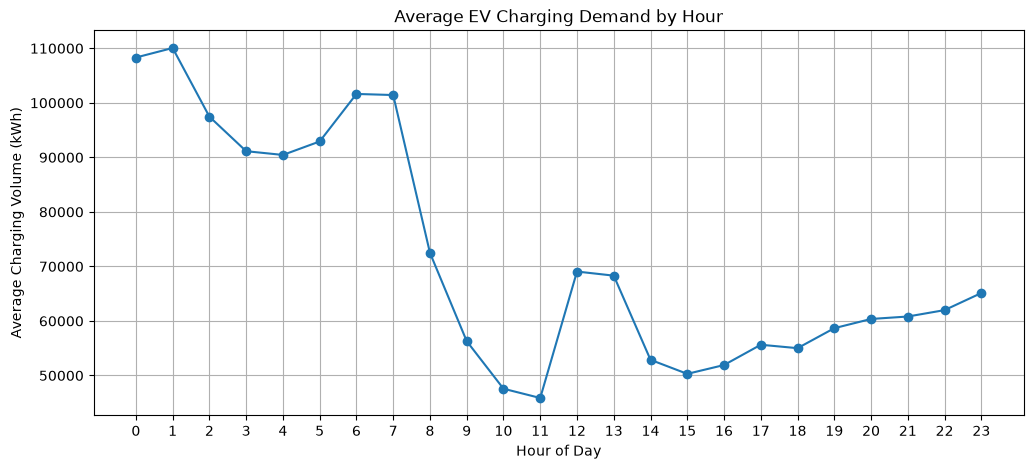

In [16]:
hourly_data = pd.DataFrame({
    "time": volume["time"],
    "total_demand": total_demand
})

hourly_data["hour"] = hourly_data["time"].dt.hour

mean_by_hour = (
    hourly_data
    .groupby("hour")["total_demand"]
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    mean_by_hour.index,
    mean_by_hour.values,
    marker="o"
)

plt.title("Average EV Charging Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Charging Volume (kWh)")
plt.xticks(range(24))
plt.grid(True)

plt.show()

## Cell 15 — Average demand by day

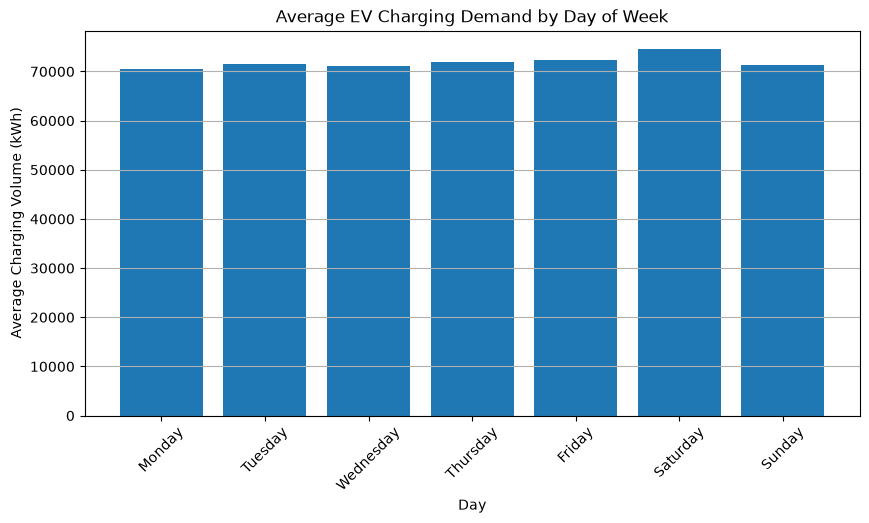

In [17]:
hourly_data["day_of_week"] = hourly_data["time"].dt.day_name()

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

mean_by_day = (
    hourly_data
    .groupby("day_of_week")["total_demand"]
    .mean()
    .reindex(day_order)
)

plt.figure(figsize=(10, 5))

plt.bar(
    mean_by_day.index,
    mean_by_day.values
)

plt.title("Average EV Charging Demand by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Charging Volume (kWh)")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

## Cell 16 — Demand distribution

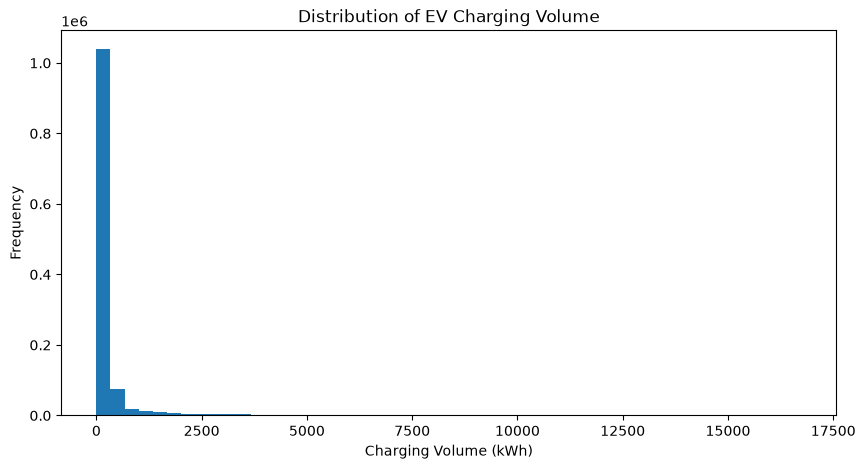

In [18]:
plt.figure(figsize=(10, 5))

plt.hist(
    volume_values.values.flatten(),
    bins=50
)

plt.title("Distribution of EV Charging Volume")
plt.xlabel("Charging Volume (kWh)")
plt.ylabel("Frequency")

plt.show()

## Cell 17 — Total demand per zone

In [19]:
zone_total_demand = volume_values.sum(axis=0)

top_zones = (
    zone_total_demand
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 zones by total charging demand:")

display(top_zones)

Top 10 zones by total charging demand:


595     2.931878e+07
1167    2.181163e+07
844     1.682888e+07
633     1.500420e+07
1026    1.378514e+07
775     1.338669e+07
592     1.280403e+07
777     1.202707e+07
690     1.174409e+07
346     8.429800e+06
dtype: float64

## Cell 18 — Plot top zones

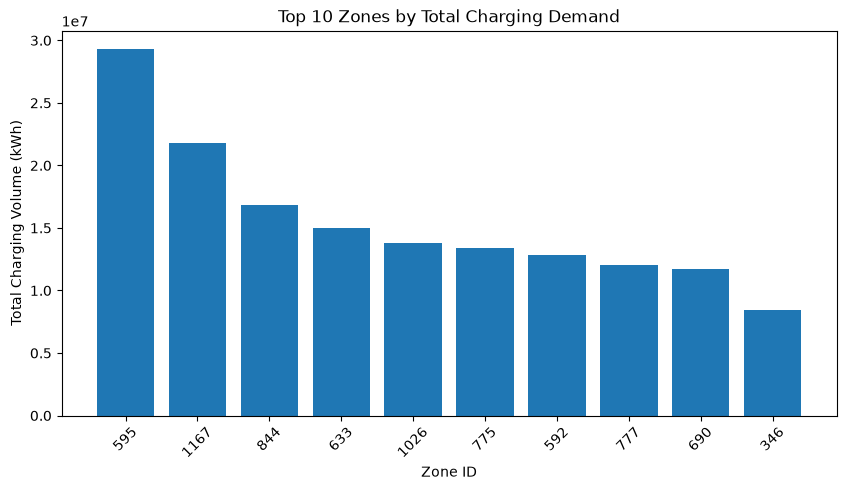

In [20]:
plt.figure(figsize=(10, 5))

plt.bar(
    top_zones.index.astype(str),
    top_zones.values
)

plt.title("Top 10 Zones by Total Charging Demand")
plt.xlabel("Zone ID")
plt.ylabel("Total Charging Volume (kWh)")
plt.xticks(rotation=45)

plt.show()

## Cell 19 — Load spatial files

In [21]:
adj_path = RAW_DATA / "adj.csv"
distance_path = RAW_DATA / "distance.csv"
zone_info_path = RAW_DATA / "zone-information.csv"

adj = pd.read_csv(adj_path, header=None)
distance = pd.read_csv(distance_path, header=None)
zone_info = pd.read_csv(zone_info_path)

print("Adjacency shape:", adj.shape)
print("Distance shape:", distance.shape)
print("Zone information shape:", zone_info.shape)

Adjacency shape: (276, 275)
Distance shape: (276, 275)
Zone information shape: (275, 6)


## Cell 20 — Zone information

In [22]:
print("Zone information columns:")
print(zone_info.columns.tolist())

display(zone_info.head())

Zone information columns:
['TAZID', 'longitude', 'latitude', 'charge_count', 'area', 'perimeter']


,TAZID,longitude,latitude,charge_count,area,perimeter
0,1066,113.910301,22.521287,40,1.577893e+06,5119.3013
1,1068,113.918680,22.517837,271,1.405269e+06,5460.2638
2,1096,113.919902,22.531428,70,1.074909e+06,4437.0676
3,326,113.931887,22.535775,106,1.963022e+06,6447.5728
4,1085,113.925789,22.521524,59,3.878395e+05,2688.3240


## Cell 21 — Final summary

In [23]:
summary = {
    "Number of timestamps": volume["time"].nunique(),
    "Number of columns": volume.shape[1],
    "Number of zones": len(zone_columns),
    "Missing values": volume.isnull().sum().sum(),
    "Duplicate timestamps": volume["time"].duplicated().sum(),
    "Start time": volume["time"].min(),
    "End time": volume["time"].max()
}

print(summary)

{'Number of timestamps': 4344, 'Number of columns': 276, 'Number of zones': 275, 'Missing values': np.int64(0), 'Duplicate timestamps': np.int64(0), 'Start time': Timestamp('2022-09-01 00:00:00'), 'End time': Timestamp('2023-02-28 23:00:00')}
